# Lista de Exercícios 07 – Raízes de Equações – Secantes

Aluna: Maria Eduarda Saldanha Alves - 25/10/2026

## 1 - Utilize o método das secantes para encontre a raiz aproximada das seguintes equações. Considere os seguintes pontos:
- Precisão de 6 casas decimais;
- Número máximo de 50 iterações e $\epsilon < 10^{-5}$;
- Isole o intervalo da raiz;
- Analise a convergência do método;
- Apresente o código, solução e passo a passo para chegar nas respostas.

### Implementação

Para encontrar as raízes aproximadas das funções propostas, será utilizado o método das secantes, que calcula novas aproximações a partir de duas estimativas anteriores. Inicialmente, será analisado o gráfico de cada função e avaliados alguns valores para escolher um intervalo que contenha uma raiz. Em seguida, o método será aplicado com tolerância \(\epsilon < 10^{-5}\) e limite máximo de 50 iterações. Para cada função, serão apresentados o código utilizado, a tabela de iterações, a raiz aproximada com seis casas decimais e a análise da convergência. Também será demonstrado o cálculo da primeira iteração e de seu erro.

In [492]:
import numpy as np
import sympy as sy
import matplotlib.pyplot as pyplot
from IPython.display import Math
from secantes import secantes

x = sy.Symbol('x')

def plot(fx, intervalo):
    xx = np.linspace(intervalo[0], intervalo[1])
    pyplot.plot(xx, fx(xx), label='f(x)')
    pyplot.grid()
    pyplot.show()

### a) $f(x) = \dfrac{ x \cos{(x^3 + 1)}}{2}$

<IPython.core.display.Math object>

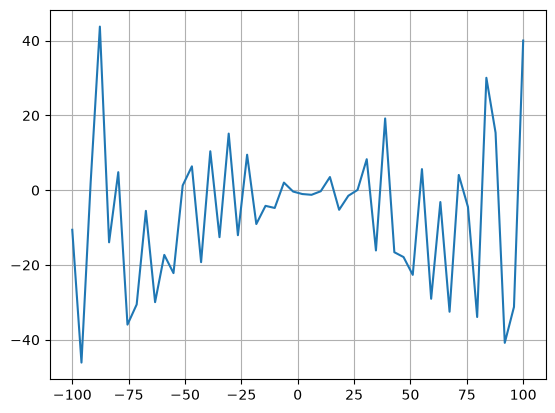

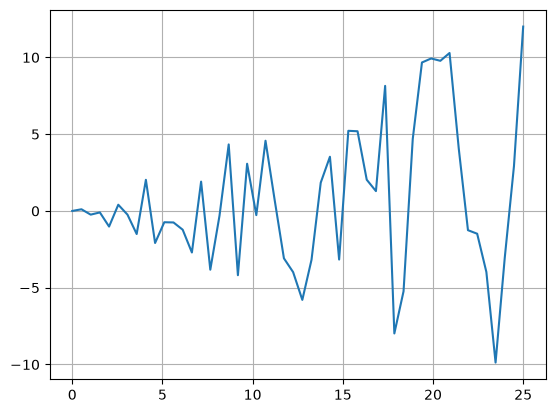

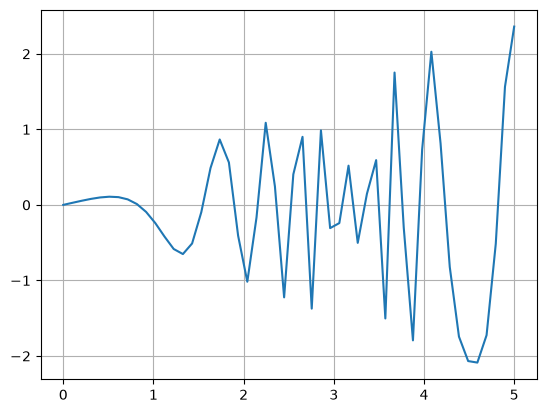

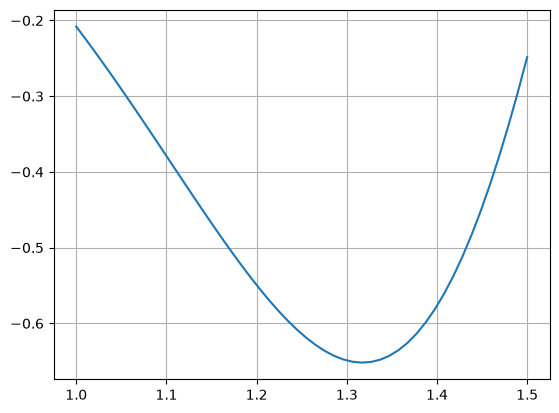

In [493]:
# Definição do intervalo
fx_ = sy.cos(x**3+1) * x/2
display(Math('f(x) = ' + sy.latex(fx_)))
fx = sy.lambdify(x, fx_)
plot(fx, [-100, 100])
plot(fx, [0, 25])
plot(fx, [0, 5])
plot(fx, [1, 1.5])

In [494]:
print(f'f(1) = {fx(1)}')
print(f'f(1.5) = {fx(1.5)}')

f(1) = -0.2080734182735712
f(1.5) = -0.24826830543966555


In [495]:
for i in [0, 0.5, 1, 1.5, 2, 2.5, 3]:
    print(f'f({i}) = {fx(i):.6f}')

f(0) = 0.000000
f(0.5) = 0.107794
f(1) = -0.208073
f(1.5) = -0.248268
f(2) = -0.911130
f(2.5) = -0.760219
f(3) = -1.443909


In [496]:
# Definição do intervalo
intervalo = [0.5, 1]

# Aplicação do método das secantes
raiz, iteracoes = secantes(fx_, intervalo, 1e-5, 50)

display(iteracoes)
print(f'Raiz aproximada: {raiz:.6f}')

,Iteração,x,x anterior,f(x),f(x anterior),Erro
0,1,0.670632,1.000000,8.917479e-02,-0.208073,0.329368
1,2,0.769443,0.670632,4.424255e-02,0.089175,0.098811
2,3,0.866737,0.769443,-3.477273e-02,0.044243,0.097294
3,4,0.823920,0.866737,4.730477e-03,-0.034773,0.042817
4,5,0.829047,0.823920,4.046274e-04,0.004730,0.005127
5,6,0.829527,0.829047,-5.533572e-06,0.000405,0.000480
6,7,0.829520,0.829527,6.317796e-09,-0.000006,0.000006


Raiz aproximada: 0.829520


**Análise da convergência:** O método das secantes convergiu após 7 iterações, encontrando a raiz aproximada x = 0.829520. O valor da função nessa aproximação é próximo de zero, e o erro final ficou abaixo da tolerância estabelecida de 10^-5. Portanto, o critério de parada foi satisfeito.

In [497]:
# Cálculo da primeira iteração

x0 = 0.5
x1 = 1

f0 = fx(x0)
f1 = fx(x1)

x2 = x1 - f1 * (x1 - x0) / (f1 - f0)

print(f'f(x0) = {f0:.6f}')
print(f'f(x1) = {f1:.6f}')
print(f'Nova aproximação x2 = {x2:.6f}')

f(x0) = 0.107794
f(x1) = -0.208073
Nova aproximação x2 = 0.670632


In [498]:
# Cálculo do erro da primeira iteração

erro = abs(x2 - x1) / max(abs(x2), 1)

print(f'Erro da primeira iteração: {erro:.6f}')
print(f'Tolerância exigida: {1e-5}')

Erro da primeira iteração: 0.329368
Tolerância exigida: 1e-05


### b) $f(x) = e^\frac{\cos{(x)}}{2} - 1$

<IPython.core.display.Math object>

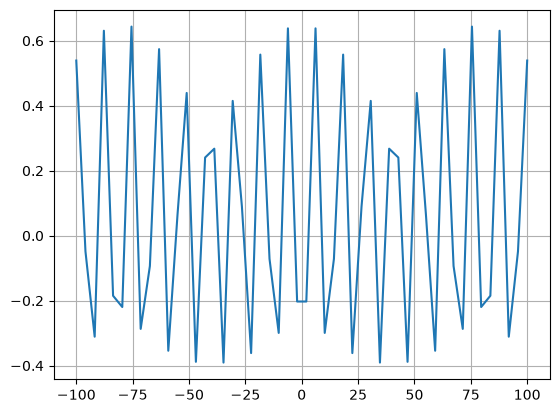

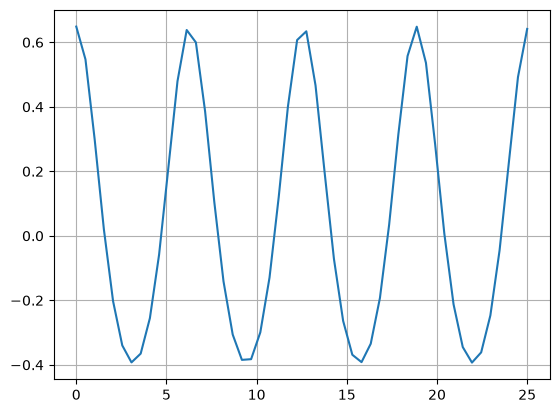

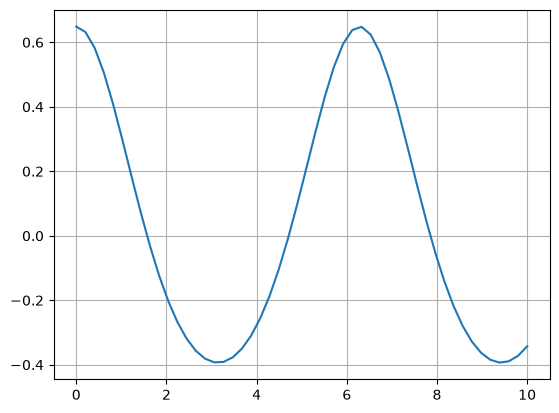

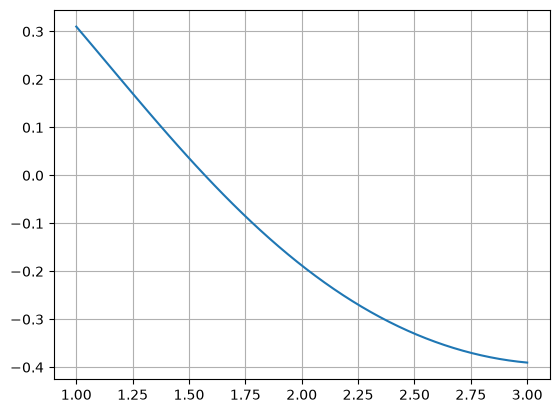

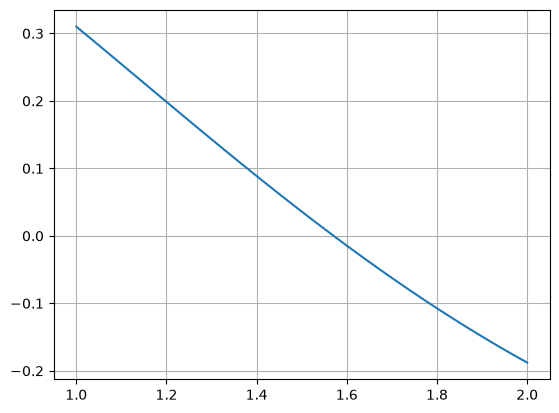

In [499]:
# Definição da função
x = sy.Symbol('x')
fx_ = sy.exp(sy.cos(x)/2) - 1

display(Math('f(x) = ' + sy.latex(fx_)))

fx = sy.lambdify(x, fx_)

plot(fx, [-100, 100])
plot(fx, [0, 25])
plot(fx, [0, 10])
plot(fx, [1, 3])
plot(fx, [1, 2])

In [500]:
print(f'f(1) = {fx(1)}')
print(f'f(2) = {fx(2)}')

f(1) = 0.3101624706687731
f(2) = -0.18785259193753567


In [501]:
# Definição do intervalo
intervalo = [1, 2]

# Aplicação do método das secantes
raiz, iteracoes = secantes(fx_, intervalo, 1e-5, 50)

display(iteracoes)
print(f'Raiz aproximada: {raiz:.6f}')

,Iteração,x,x anterior,f(x),f(x anterior),Erro
0,1,1.622797,2.000000,-2.565400e-02,-1.878526e-01,2.324398e-01
1,2,1.563137,1.622797,3.836750e-03,-2.565400e-02,3.816679e-02
2,3,1.570899,1.563137,-5.143466e-05,3.836750e-03,4.940969e-03
3,4,1.570797,1.570899,-9.792751e-08,-5.143466e-05,6.536563e-05
4,5,1.570796,1.570797,2.518874e-12,-9.792751e-08,1.246884e-07


Raiz aproximada: 1.570796


**Análise da convergência:** O intervalo inicial escolhido foi [1,2], no qual a função apresenta sinais opostos nas extremidades. O método das secantes convergiu após 5 iterações, encontrando a raiz aproximada x=1.570796. O erro final foi de aproximadamente 1.246884e-07, valor inferior à tolerância estabelecida de 10^-5. Portanto, o critério de parada foi satisfeito.

In [502]:
# Cálculo da primeira iteração

x0 = 1
x1 = 2

f0 = fx(x0)
f1 = fx(x1)

x2 = x1 - f1 * (x1 - x0) / (f1 - f0)

print(f'f(x0) = {f0:.6f}')
print(f'f(x1) = {f1:.6f}')
print(f'Nova aproximação x2 = {x2:.6f}')

f(x0) = 0.310162
f(x1) = -0.187853
Nova aproximação x2 = 1.622797


In [503]:
# Cálculo do erro da primeira iteração

erro = abs(x2 - x1) / max(abs(x2), 1)

print(f'Erro da primeira iteração: {erro:.6f}')
print(f'Tolerância exigida: {1e-5}')

Erro da primeira iteração: 0.232440
Tolerância exigida: 1e-05


### c) $f(x) = x^5 - 3x^3 + 2x^2 - 5x + 10$

<IPython.core.display.Math object>

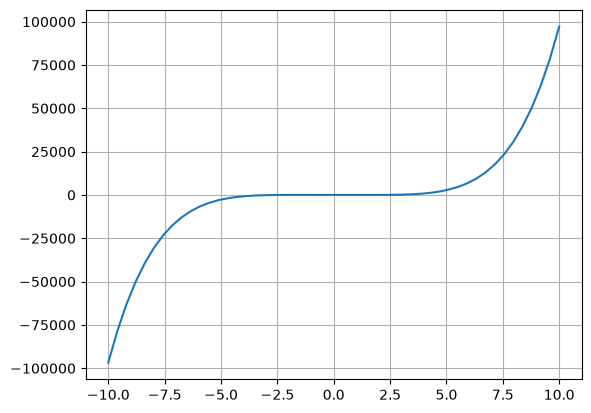

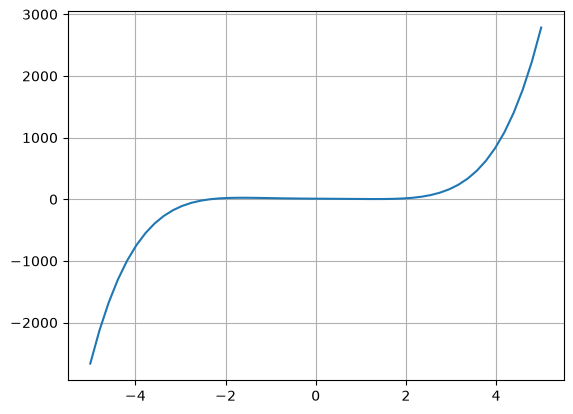

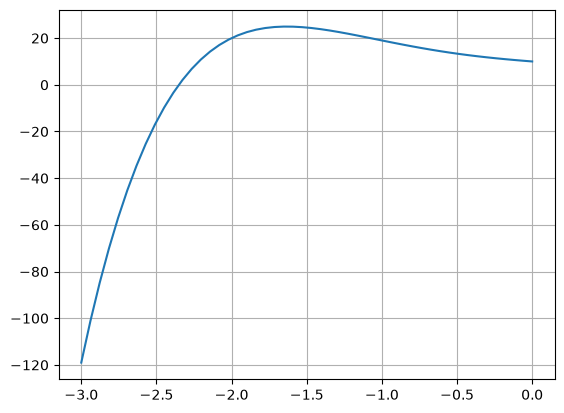

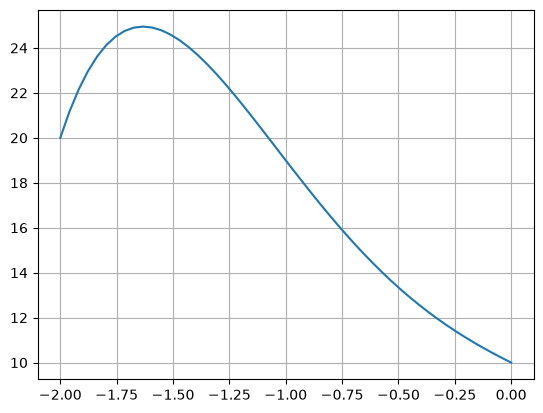

In [504]:
# Definição da função
x = sy.Symbol('x')
fx_ = x**5 - 3*x**3 + 2*x**2 - 5*x + 10

display(Math('f(x) = ' + sy.latex(fx_)))

fx = sy.lambdify(x, fx_)

plot(fx, [-10, 10])
plot(fx, [-5, 5])
plot(fx, [-3, 0])
plot(fx, [-2, 0])

In [505]:
print(f'f(-2) = {fx(-2)}')
print(f'f(0) = {fx(0)}')
print(f'f(-3) = {fx(-3)}')
print(f'f(-4) = {fx(-4)}')

f(-2) = 20
f(0) = 10
f(-3) = -119
f(-4) = -770


In [506]:
# Definição do intervalo
intervalo = [-3, -2]

# Aplicação do método das secantes
raiz, iteracoes = secantes(fx_, intervalo, 1e-5, 50)

display(iteracoes)
print(f'Raiz aproximada: {raiz:.6f}')

,Iteração,x,x anterior,f(x),f(x anterior),Erro
0,1,-2.143885,-2.000000,1.418283e+01,20.000000,6.711409e-02
1,2,-2.494691,-2.143885,-1.512625e+01,14.182832,1.406209e-01
2,3,-2.313642,-2.494691,3.133461e+00,-15.126249,7.825273e-02
3,4,-2.344711,-2.313642,5.228466e-01,3.133461,1.325064e-02
4,5,-2.350933,-2.344711,-2.425296e-02,0.522847,2.646777e-03
5,6,-2.350657,-2.350933,1.745860e-04,-0.024253,1.173456e-04
6,7,-2.350659,-2.350657,5.763408e-08,0.000175,8.386791e-07


Raiz aproximada: -2.350659


**Análise da convergência:** O intervalo inicial escolhido foi [-3,-2], no qual a função apresenta sinais opostos nas extremidades. O método das secantes convergiu após 7 iterações, encontrando a raiz aproximada x=-2.350659. O erro final foi de aproximadamente 8.386791e-07, valor inferior à tolerância estabelecida de 10^-5. Portanto, o critério de parada foi satisfeito.

In [507]:
# Cálculo da primeira iteração

x0 = -3
x1 = -2

f0 = fx(x0)
f1 = fx(x1)

x2 = x1 - f1 * (x1 - x0) / (f1 - f0)

print(f'f(x0) = {f0:.6f}')
print(f'f(x1) = {f1:.6f}')
print(f'Nova aproximação x2 = {x2:.6f}')

f(x0) = -119.000000
f(x1) = 20.000000
Nova aproximação x2 = -2.143885


In [508]:
# Cálculo do erro da primeira iteração

erro = abs(x2 - x1) / max(abs(x2), 1)

print(f'Erro da primeira iteração: {erro:.6f}')
print(f'Tolerância exigida: {1e-5}')

Erro da primeira iteração: 0.067114
Tolerância exigida: 1e-05


### d) $f(x) = \dfrac{(x^4 - 3x^3 - 5x^2) \sin(x)}{x^3 + 10}$

<IPython.core.display.Math object>

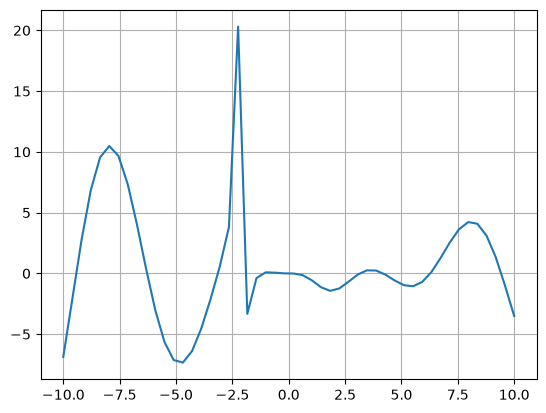

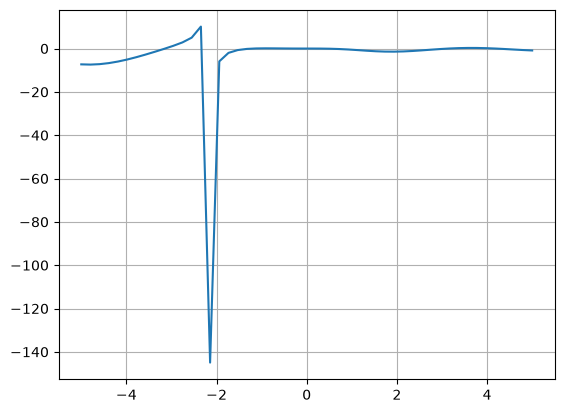

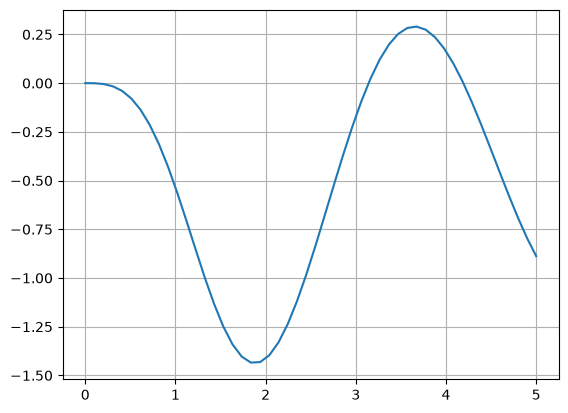

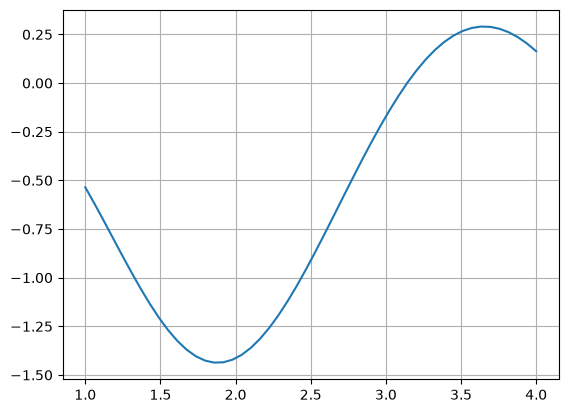

In [509]:
# Definição da função
x = sy.Symbol('x')
fx_ = ((x**4 - 3*x**3 - 5*x**2) * sy.sin(x)) / (x**3 + 10)

display(Math('f(x) = ' + sy.latex(fx_)))

fx = sy.lambdify(x, fx_)

plot(fx, [-10, 10])
plot(fx, [-5, 5])
plot(fx, [0, 5])
plot(fx, [1, 4])

In [510]:
print(f'f(1) = {fx(1)}')
print(f'f(4) = {fx(4)}')

f(1) = -0.5354815357868432
f(4) = 0.16363297195847096


In [511]:
# Definição do intervalo
intervalo = [1, 4]

# Aplicação do método das secantes
raiz, iteracoes = secantes(fx_, intervalo, 1e-5, 50)

display(iteracoes)
print(f'Raiz aproximada: {raiz:.6f}')

,Iteração,x,x anterior,f(x),f(x anterior),Erro
0,1,3.297828,4.000000,1.482396e-01,0.163633,2.129197e-01
1,2,-3.464166,3.297828,-2.095776e+00,0.148240,1.951983e+00
2,3,2.851130,-3.464166,-3.806468e-01,-2.095776,2.215015e+00
3,4,4.252714,2.851130,-6.106291e-02,-0.380647,3.295739e-01
4,5,4.520515,4.252714,-3.671010e-01,-0.061063,5.924119e-02
5,6,4.199281,4.520515,-6.601485e-03,-0.367101,7.649743e-02
6,7,4.193398,4.199281,-8.011734e-04,-0.006601,1.402790e-03
7,8,4.192586,4.193398,-3.210030e-06,-0.000801,1.937992e-04
8,9,4.192582,4.192586,-1.582387e-09,-0.000003,7.796118e-07


Raiz aproximada: 4.192582


**Análise da convergência:** O intervalo inicial escolhido foi [1,4], no qual a função apresenta sinais opostos nas extremidades. O método das secantes convergiu após 9 iterações, encontrando a raiz aproximada x=4.192582. O erro final foi de aproximadamente 7.796118e-07, valor inferior à tolerância estabelecida de 10^-5. Portanto, o critério de parada foi satisfeito.

In [512]:
# Cálculo da primeira iteração

x0 = 1
x1 = 4

f0 = fx(x0)
f1 = fx(x1)

x2 = x1 - f1 * (x1 - x0) / (f1 - f0)

print(f'f(x0) = {f0:.6f}')
print(f'f(x1) = {f1:.6f}')
print(f'Nova aproximação x2 = {x2:.6f}')

f(x0) = -0.535482
f(x1) = 0.163633
Nova aproximação x2 = 3.297828


In [513]:
# Cálculo do erro da primeira iteração

erro = abs(x2 - x1) / max(abs(x2), 1)

print(f'Erro da primeira iteração: {erro:.6f}')
print(f'Tolerância exigida: {1e-5}')

Erro da primeira iteração: 0.212920
Tolerância exigida: 1e-05


### e) $f(x) = x^5 - 5x^4 - 7x^3 + 4x^2 - 6$

<IPython.core.display.Math object>

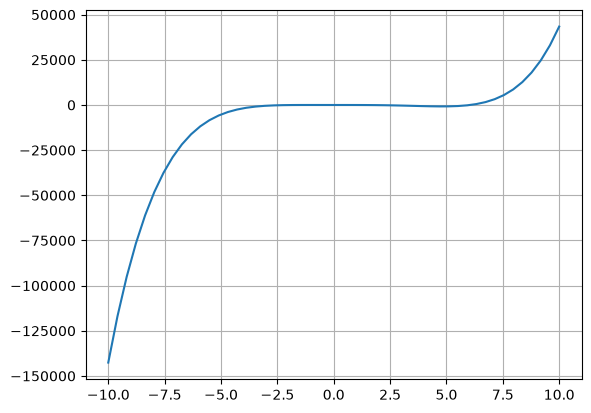

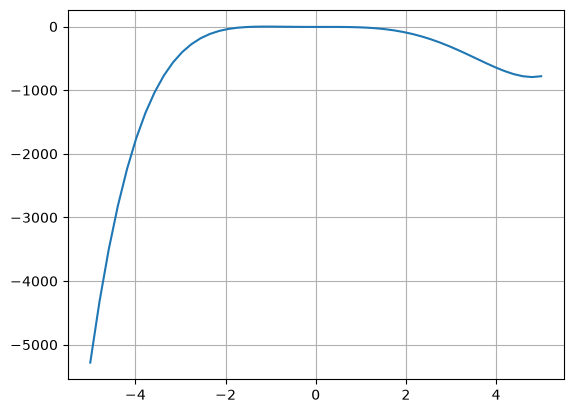

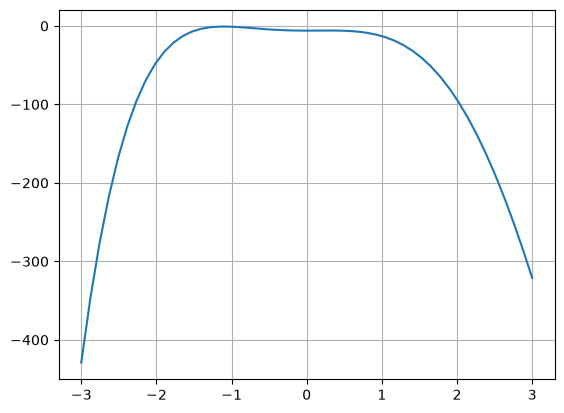

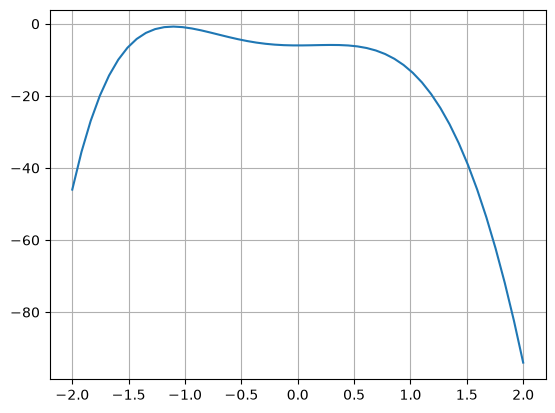

In [514]:
# Definição da função
x = sy.Symbol('x')
fx_ = x**5 - 5*x**4 - 7*x**3 + 4*x**2 - 6

display(Math('f(x) = ' + sy.latex(fx_)))

fx = sy.lambdify(x, fx_)

plot(fx, [-10, 10])
plot(fx, [-5, 5])
plot(fx, [-3, 3])
plot(fx, [-2, 2])

In [515]:
print(f'f(-2) = {fx(-2)}')
print(f'f(-1) = {fx(-1)}')
print(f'f(1) = {fx(1)}')
print(f'f(2) = {fx(2)}')
print(f'f(3) = {fx(3)}')
print(f'f(5) = {fx(5)}')
print(f'f(6) = {fx(6)}')
print(f'f(7) = {fx(7)}')
print(f'f(8) = {fx(8)}')

f(-2) = -46
f(-1) = -1
f(1) = -13
f(2) = -94
f(3) = -321
f(5) = -781
f(6) = -78
f(7) = 2591
f(8) = 8954


In [516]:
# Definição do intervalo
intervalo = [6, 7]

# Aplicação do método das secantes
raiz, iteracoes = secantes(fx_, intervalo, 1e-5, 50)

display(iteracoes)
print(f'Raiz aproximada: {raiz:.6f}')

,Iteração,x,x anterior,f(x),f(x anterior),Erro
0,1,6.029224,7.000000,-3.474210e+01,2591.000000,1.610117e-01
1,2,6.042069,6.029224,-1.520277e+01,-34.742099,2.125872e-03
2,3,6.052063,6.042069,2.252798e-01,-15.202771,1.651325e-03
3,4,6.051917,6.052063,-1.426185e-03,0.225280,2.411316e-05
4,5,6.051918,6.051917,-1.324254e-07,-0.001426,1.516935e-07


Raiz aproximada: 6.051918


**Análise da convergência:** O intervalo inicial escolhido foi [6,7], no qual a função apresenta sinais opostos nas extremidades. O método das secantes convergiu após 5 iterações, encontrando a raiz aproximada x=6.051918. O erro final foi de aproximadamente 1.516935e-07, valor inferior à tolerância estabelecida de 10^-5. Portanto, o critério de parada foi satisfeito.

In [517]:
# Cálculo da primeira iteração

x0 = 6
x1 = 7

f0 = fx(x0)
f1 = fx(x1)

x2 = x1 - f1 * (x1 - x0) / (f1 - f0)

print(f'f(x0) = {f0:.6f}')
print(f'f(x1) = {f1:.6f}')
print(f'Nova aproximação x2 = {x2:.6f}')

f(x0) = -78.000000
f(x1) = 2591.000000
Nova aproximação x2 = 6.029224


In [518]:
# Cálculo do erro da primeira iteração

erro = abs(x2 - x1) / max(abs(x2), 1)

print(f'Erro da primeira iteração: {erro:.6f}')
print(f'Tolerância exigida: {1e-5}')

Erro da primeira iteração: 0.161012
Tolerância exigida: 1e-05
